# Panel Fixed Effects

## Alcance y pregunta

¿El estimador within elimina heterogeneidad fija correlacionada con el regresor?

**Laboratorio estructural sintético.** La ampliación semanal sustituye el baseline OLS genérico por un experimento del mecanismo anunciado. No contiene estimaciones de datos de Colombia ni evidencia de desempeño productivo.

## Modelo y mecanismo

$$y_{it}=\alpha_i+\beta x_{it}+u_{it}$$

Panel balanceado de 100 entidades y 8 períodos. El regresor incluye un componente correlacionado con el efecto fijo. Se compara OLS agrupado y regresión demeaned por entidad; β=0.8.

### Supuestos de identificación

Exogeneidad estricta condicional a efecto fijo; variación temporal suficiente; sin rezago de y.

La verdad del DGP es conocida por construcción. Recuperar esa verdad comprueba implementación y diseño; no establece que el mecanismo describa una población observada.

## Configuración reproducible

Se usan NumPy, SciPy, Pandas y Matplotlib del entorno de investigación del repositorio. La semilla es fija, todos los cálculos se ejecutan desde los inputs y ninguna celda lee resultados precomputados. OLS incluye intercepto salvo fórmulas que lo excluyen explícitamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
COLORS=['#245C83','#B56A20','#637843']
SEED=20261018
REPLICATIONS=40

def ols_fit(y, regressors):
    """Intercept included; QR/SVD-backed least squares, no matrix inversion."""
    X=np.column_stack([np.ones(len(y)),regressors])
    coefficients,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('Diseño sin rango completo')
    return coefficients,y-X@coefficients

def ar_process(rng,n,rho):
    if abs(rho)>=1: raise ValueError('Se requiere AR estacionario')
    draws=rng.normal(size=n+200); x=np.zeros(n+200)
    for t in range(1,len(x)): x[t]=rho*x[t-1]+draws[t]
    return x[200:]


## Datos y experimento

Panel balanceado de 100 entidades y 8 períodos. El regresor incluye un componente correlacionado con el efecto fijo. Se compara OLS agrupado y regresión demeaned por entidad; β=0.8.

El siguiente código define el DGP o problema de equilibrio y sus comparadores. Las restricciones, oráculos analíticos y condiciones de factibilidad que corresponden al mecanismo se comprueban dentro de la función. Las cantidades monetarias se expresan en unidades sintéticas.

In [2]:
def experiment(rng,level,n=500):
    units=100;periods=8;effect=rng.normal(size=(units,1))
    x=level*effect+rng.normal(size=(units,periods));y=effect+.8*x+rng.normal(scale=.5,size=x.shape)
    pooled=ols_fit(y.ravel(),x.reshape(-1,1))[0][1]
    xd=x-x.mean(axis=1,keepdims=True);yd=y-y.mean(axis=1,keepdims=True)
    within=np.sum(xd*yd)/np.sum(xd*xd)
    return {'OLS agrupado':pooled,'Efectos fijos within':within,'β real':.8},(x.ravel(),y.ravel())


### Un escenario reproducible

Cada métrica conserva su denominador y unidad conceptual; no se mezclan conteos, probabilidades y costos en un mismo eje. La tabla muestra el caso central de la malla, antes de resumir réplicas.

In [3]:
GRID=[0, 0.25, 0.5, 1.0, 2.0]
METRICS=['OLS agrupado', 'Efectos fijos within', 'β real']
central=GRID[len(GRID)//2]
example,diagnostic=experiment(np.random.default_rng(SEED),central)
display(pd.DataFrame({'Métrica':list(example),'Valor':list(example.values())}))
print('Escenario central:',central,'; semilla:',SEED)


Escenario central: 0.5 ; semilla: 20261018


,Métrica,Valor
0,OLS agrupado,1.296526
1,Efectos fijos within,0.814280
2,β real,0.800000


## Sensibilidad y variación entre réplicas

**Eje:** Correlación por construcción λ.

Se conservan 40 réplicas por escenario. Se reinicia la misma secuencia de semillas para cada nivel: las comparaciones entre niveles comparten innovaciones cuando la dimensión del DGP lo permite. En mecanismos deterministas los cuantiles coinciden; esto no representa una incertidumbre estimada de parámetros. No se descartan resultados desfavorables.

In [4]:
records=[]
for level in GRID:
    for replicate in range(REPLICATIONS):
        metrics,_=experiment(np.random.default_rng(SEED+replicate),level)
        if set(metrics)!=set(METRICS): raise AssertionError('Métricas inconsistentes')
        for name,value in metrics.items():
            if not np.isfinite(value):raise ArithmeticError(f'Resultado no finito: {name}')
            records.append({'nivel':level,'replica':replicate,'metrica':name,'valor':float(value)})
raw=pd.DataFrame(records)
summary=raw.groupby(['nivel','metrica'],sort=False).valor.agg(
    media='mean',mediana='median',sd_replicas='std',
    q025=lambda x:x.quantile(.025),q975=lambda x:x.quantile(.975),n='size').reset_index()
summary['se_media_mc']=summary.sd_replicas/np.sqrt(summary.n)
display(summary.round(5))


,nivel,metrica,media,mediana,sd_replicas,q025,q975,n,se_media_mc
0,0.00,OLS agrupado,0.80159,0.80430,0.04073,0.73453,0.87651,40,0.00644
1,0.00,Efectos fijos within,0.79848,0.79800,0.01953,0.75758,0.83132,40,0.00309
2,0.00,β real,0.80000,0.80000,0.00000,0.80000,0.80000,40,0.00000
3,0.25,OLS agrupado,1.04283,1.04056,0.04437,0.97590,1.12750,40,0.00702
4,0.25,Efectos fijos within,0.79848,0.79800,0.01953,0.75758,0.83132,40,0.00309
5,0.25,β real,0.80000,0.80000,0.00000,0.80000,0.80000,40,0.00000
6,0.50,OLS agrupado,1.20918,1.20999,0.04760,1.12180,1.29698,40,0.00753
7,0.50,Efectos fijos within,0.79848,0.79800,0.01953,0.75758,0.83132,40,0.00309
8,0.50,β real,0.80000,0.80000,0.00000,0.80000,0.80000,40,0.00000
9,1.00,OLS agrupado,1.30603,1.30468,0.03537,1.23129,1.35740,40,0.00559


### Qué muestran los intervalos

Las bandas de la figura son cuantiles 2.5–97.5% entre realizaciones del DGP, **no intervalos de confianza de un estimador en una sola muestra**. `se_media_mc` mide únicamente el error Monte Carlo de la media en este conjunto de réplicas; no mide incertidumbre económica ni corrige especificación. Se informa media y mediana para detectar asimetría, especialmente bajo identificación débil.

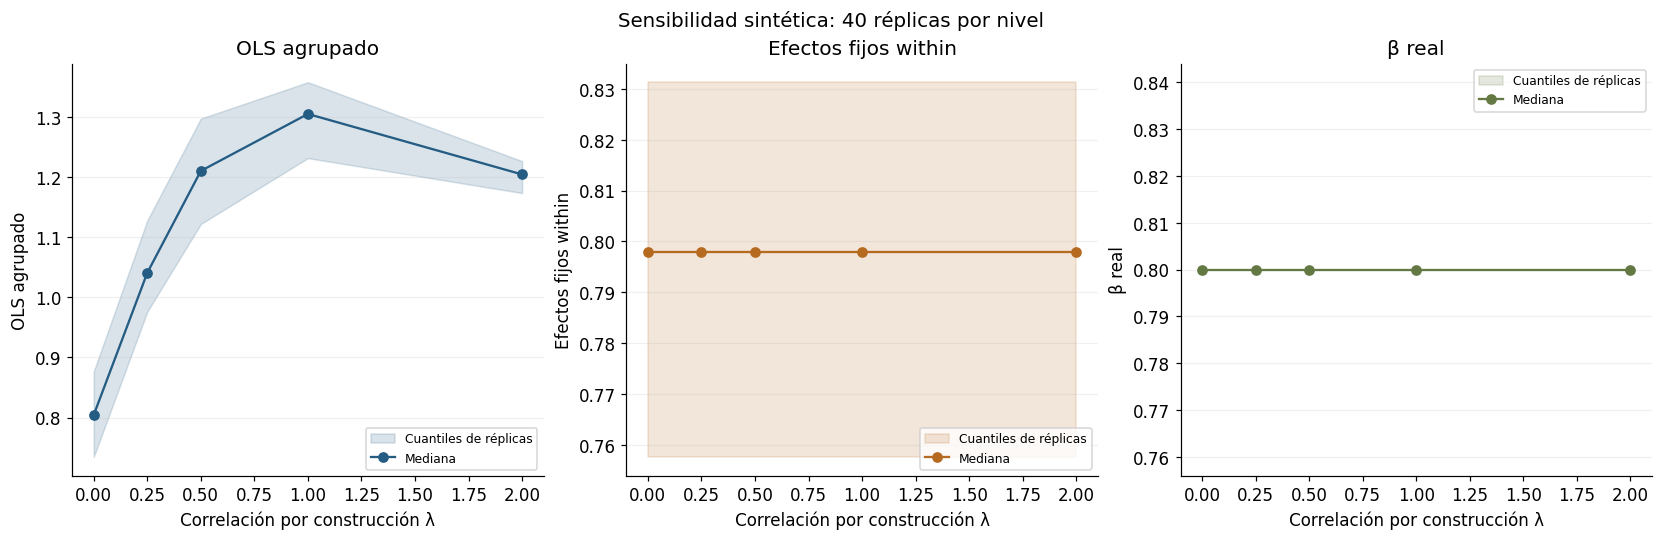

In [5]:
import textwrap
fig,axes=plt.subplots(1,len(METRICS),figsize=(15,4.8),layout='constrained')
for index,(ax,name) in enumerate(zip(np.atleast_1d(axes),METRICS)):
    group=summary[summary.metrica==name].sort_values('nivel')
    ax.fill_between(group.nivel,group.q025,group.q975,color=COLORS[index%3],alpha=.17,label='Cuantiles de réplicas')
    ax.plot(group.nivel,group.mediana,'o-',color=COLORS[index%3],label='Mediana')
    ax.set(title='\n'.join(textwrap.wrap(name,25)),xlabel='\n'.join(textwrap.wrap('Correlación por construcción λ',30)),ylabel=name)
    ax.grid(axis='y',alpha=.18); ax.legend(fontsize=8)
fig.suptitle('Sensibilidad sintética: 40 réplicas por nivel',fontsize=13)
plt.show()


## Lectura de resultados ejecutados

El contraste siguiente se calcula con las salidas de la ejecución, sin fijar de antemano el signo de la conclusión. Debe interpretarse junto con los supuestos y la variación entre réplicas.

In [6]:
for name in METRICS:
    group=summary[summary.metrica==name].sort_values('nivel')
    first,last=group.iloc[0],group.iloc[-1]
    print(f"{name}: mediana {first['mediana']:.6g} en nivel {first['nivel']:g}; "
          f"{last['mediana']:.6g} en nivel {last['nivel']:g}.")
    print(f"  Último escenario: cuantiles [{last['q025']:.6g}, {last['q975']:.6g}], "
          f"media {last['media']:.6g}, error MC de la media {last['se_media_mc']:.3g}.")


OLS agrupado: mediana 0.804295 en nivel 0; 1.20415 en nivel 2.
  Último escenario: cuantiles [1.1732, 1.22629], media 1.20218, error MC de la media 0.00221.
Efectos fijos within: mediana 0.798001 en nivel 0; 0.798001 en nivel 2.
  Último escenario: cuantiles [0.757584, 0.83132], media 0.79848, error MC de la media 0.00309.
β real: mediana 0.8 en nivel 0; 0.8 en nivel 2.
  Último escenario: cuantiles [0.8, 0.8], media 0.8, error MC de la media 0.


## Comprobaciones y controles

La reproducibilidad exige que la misma semilla reconstruya las mismas métricas. Los asserts estructurales de la función no dependen de que un estimador estocástico gane a otro en esta realización. Los conteos se reconcilian para no perder réplicas silenciosamente.

In [7]:
repeated,_=experiment(np.random.default_rng(SEED),central)
assert all(np.isclose(example[k],repeated[k],rtol=0,atol=1e-12) for k in METRICS)
assert len(raw)==len(GRID)*REPLICATIONS*len(METRICS)
assert summary.n.eq(REPLICATIONS).all()
assert (summary.q025<=summary.mediana+1e-12).all()
assert (summary.mediana<=summary.q975+1e-12).all()
print('Semilla, finitud, cuantiles y totalidad de réplicas: correctos.')


Semilla, finitud, cuantiles y totalidad de réplicas: correctos.


## Límites y siguiente contraste

Within no elimina shocks variables correlacionados con x. Inferencia con panel requiere errores agrupados; se muestran distribuciones Monte Carlo, no intervalos iid.

Antes de incorporar datos observados se debe fijar unidad de análisis, fecha de disponibilidad, reglas de exclusión y población de evaluación. La ampliación demuestra un mecanismo acotado; no convierte el proyecto en modelo validado externamente.

## Trazabilidad

Desarrollo semanal sobre `865c326`, revisión del 18-10-2026 UTC (noche del 17-10 en Colombia). El historial Git conserva el baseline genérico anterior. Todos los datos nuevos se regeneran desde la función `experiment`; las salidas del notebook se guardan después de ejecutar sus celdas de principio a fin.